# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_: 
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).
- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=-5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

### **1.)** Implementing the root finders manually to find the roots of the given function.

In [2]:
# Setting up the function and its derivative
def f(x):
    return (-x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8)

def df(x):
    return (-5*x**4 + 16*x**3 - 12*x**2 + (x**2 + 2*x)*np.exp(x) - 4*x - 4*(x + 1)*np.exp(x) + 8 + 4*np.exp(x))

In [ ]:
# Defining tolerance and maximum iterations
tol = 1.e-8
kmax = 200

#### Using **fixed-point method** with a relaxation factor $a$ and an initial guess $v_0$

root = -1.19268577, steps = 32


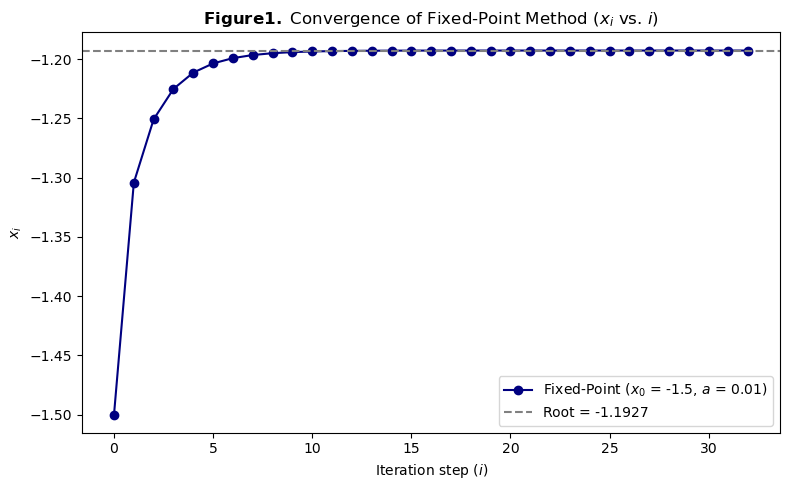

In [15]:
def fixed_point(f, x0, a=1): 
    xs = [x0]
    x = x0
    for k in range(1, kmax):
        xnew = x + a*f(x)
        xs.append(xnew)
        if abs(xnew - x) < tol:
            break
        x = xnew 
    else:
        print("fixedpoint: maxed out")
    return np.array(xs) 

# Setting initial conditions 
x0 = -1.5
a = 0.01
xs = fixed_point(f, x0, a)
root = xs[-1]
print(f"root = {root:.8f}, steps = {len(xs)-1}")

# Plotting the convergence of the values towards the root 
iterations = np.arange(len(xs))

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(iterations, xs, 'o-', color='navy',
        label=f'Fixed-Point ($x_0$ = {x0}, $a$ = {a})')
ax.axhline(root, color='gray', linestyle='--', label=f'Root = {root:.4f}')

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title(r'$\bf{Figure\ 1.}$ Convergence of Fixed-Point Method ($x_i$ vs. $i$)')

ax.grid(False)
ax.legend()

plt.tight_layout()
plt.show()

#### Using **bisection method** with bracketing and two bounds

root = -1.19268576, steps = 27


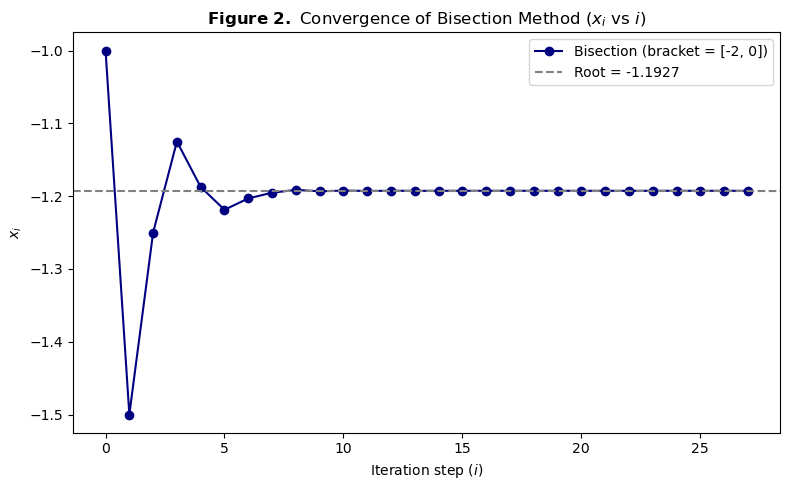

In [26]:
# Manual Implementation 
def bisection(f, x0, x1): # x0 and x1 are the two ends of the bracket
    if f(x0)*f(x1) > 0:
       raise ValueError("bisection: no sign change in bracket")
    xs = [] 
    for k in range(1, kmax):
        xs_k = 0.5*(x0 + x1)
        xs.append(xs_k)
        if f(x0)*f(xs_k) < 0:
            x1 = xs_k
        else:
            x0 = xs_k
        if abs(x1 - x0) < tol:
            break 
    else:
        print("bisection: maxed out")
    return np.array(xs) 

# Setting initial conditions 
x0 = -2
x1 = 0
a = 0
xs = bisection(f, x0, x1)
root = xs[-1]
print(f"root = {root:.8f}, steps = {len(xs)-1}")

# Plotting FIXED-POINT
iterations = np.arange(len(xs))

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(iterations, xs, 'o-', color='navy',
        label=f'Bisection (bracket = [{x0}, {x1}])')
ax.axhline(root, color='gray', linestyle='--', label=f'Root = {root:.4f}')

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title(r'$\bf{Figure\ 2.}$ Convergence of Bisection Method ($x_i$ vs $i$)')

ax.grid(False)
ax.legend()

plt.tight_layout()
plt.show()

#### Using **Newton's method**, along with the function's derivative $df$ and an initial guess $v_0$:

In [ ]:
# Manual Implementation 
def newton(f, df, x0): 
    xs = [x0]
    x = x0
    for k in range(1, kmax):
        xnew = x - f(x)/df(x)
        xs.append(xnew)
        if abs(xnew -x) < tol:
            break
        x = xnew 
    else:
        print("newton: maxed out")
    return np.array(xs)
    
# Setting initial conditions 
x0 = -2
xs = newton(f, df, x0)
root = xs[-1]
print(f"root = {root:.8f}, steps = {len(xs)-1}")

# Plotting Newton
iterations = np.arange(len(xs))

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(iterations, xs, 'o-', color='navy',
        label=f'Newton ($x_0$ = {x0})')
ax.axhline(root, color='gray', linestyle='--', label=f'Root = {root:.4f}')

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title('Convergence of Newton Method ($x_i$ vs $i$)')

ax.grid(False)
ax.legend()

plt.tight_layout()
plt.show()